In [2]:
# Pt 2. Data Analysis and Lipinski Descriptor Calculation
import sys
import rdkit
from rdkit import Chem
import pandas as pd

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("RDKit version:", rdkit.__version__)

Python executable: c:\Users\Andina Angelia\anaconda3\python.exe
Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
RDKit version: 2026.09.1


In [4]:
# Open the CSV file and read it into a DataFrame
df = pd.read_csv('bioactivity_data_curated.csv')
df.head()  # Display the first few rows of the DataFrame

,molecule_chembl_id,canonical_smiles,standard_value,class
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0,active
1,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0,active
2,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,9300.0,intermediate
3,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,500000.0,inactive
4,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,3000000.0,inactive


In [5]:
# Import necessary libraries for machine learning
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

# Calculate Lipinski descriptors
# evaluating the druglikeness of compounds. Such druglikeness 
# is based on the Absorption, Distribution, Metabolism and Excretion (ADME)
# Lipinski analyzed all orally active FDA-approved drugs in the formulation of 
# what is to be known as the Rule-of-Five or Lipinski's Rule

# The Lipinski's Rule stated the following:
# Molecular weight < 500 Dalton
# Octanol-water partition coefficient (LogP) < 5
# Hydrogen bond donors < 5
# Hydrogen bond acceptors < 10

In [6]:
# Inspired by: https://codeocean.com/explore/capsules?query=tag:data-curation

def lipinski(smiles, verbose=False):
    moldata = []
    for elem in smiles:
        mol = Chem.MolFromSmiles(elem)
        moldata.append(mol)
    
    baseData = np.arange(1,1)
    i = 0

    for mol in moldata:
        desc_MolWt = Descriptors.MolWt(mol)
        desc_MolLogP = Descriptors.MolLogP(mol)
        desc_NumHDonors = Lipinski.NumHDonors(mol)
        desc_NumHAcceptors = Lipinski.NumHAcceptors(mol)

        row = np.array([desc_MolWt,
                        desc_MolLogP,
                        desc_NumHDonors,
                        desc_NumHAcceptors])
        
        if(i==0):
            baseData = row
        else:
            baseData = np.vstack([baseData, row])
        
        i += 1
    
    columnNames = ["MolWt", "MolLogP", "NumHDonors", "NumHAcceptors"]
    descriptors = pd.DataFrame(data=baseData, columns=columnNames)

    return descriptors

In [7]:
df_lipinski = lipinski(df.canonical_smiles)
df_lipinski  # Display the first few rows of the Lipinski descriptors DataFrame

,MolWt,MolLogP,NumHDonors,NumHAcceptors
0,383.814,4.45034,3.0,4.0
1,482.903,3.61432,3.0,6.0
2,369.432,4.77200,1.0,6.0
3,283.287,2.31056,2.0,4.0
4,164.160,1.49000,2.0,2.0
...,...,...,...,...
786,416.477,4.89872,3.0,3.0
787,326.352,2.84162,3.0,3.0
788,354.362,2.83964,4.0,3.0
789,402.450,4.50862,3.0,3.0


In [8]:
# Combine DataFrames
df_combined = pd.concat([df, df_lipinski], axis=1)
df_combined.head()  # Display the first few rows of the combined DataFrame

,molecule_chembl_id,canonical_smiles,standard_value,class,MolWt,MolLogP,NumHDonors,NumHAcceptors
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0,active,383.814,4.45034,3.0,4.0
1,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0,active,482.903,3.61432,3.0,6.0
2,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,9300.0,intermediate,369.432,4.77200,1.0,6.0
3,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,500000.0,inactive,283.287,2.31056,2.0,4.0
4,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,3000000.0,inactive,164.160,1.49000,2.0,2.0


In [11]:
# The standard value has to be capped to 1e^8, otherwise the pIC50 will be negative and this is not possible.
def norm_value(input):
    norm_value = []

    for i in input['standard_value']:
        if i > 100000000:
            norm_value.append(100000000)
        else:
            norm_value.append(i)
    
    input['standard_value_norm'] = norm_value  # Add standard_value_norm column to the DataFrame
    x = input.drop('standard_value', axis=1)  # Drop the standard_value column
    return x

In [12]:
# Convert IC50 to pIC50 to the negative logarithmic scale
# This custom function pIC50() will accept a DataFrame as input and will:

# Take the IC50 values from the standard_value column and converts it from nM to M by multiplying the value by 1e-9
# Take the molar value and apply -log10
# Delete the standard_value column and create a new pIC50 column

def pIC50(input):
    pIC50 = []

    for i in input['standard_value_norm']:
        molar = i * 1e-9  # Convert nM to M
        pIC50_value = -np.log10(molar)  # Calculate pIC50
        pIC50.append(pIC50_value)
    
    input['pIC50'] = pIC50  # Add pIC50 column to the DataFrame
    x = input.drop('standard_value_norm', axis=1)  # Drop the standard_value_norm column
    return x

In [13]:
# Describe the standard_value column to understand its distribution and identify any potential outliers
df_combined.standard_value.describe() 

count    7.910000e+02
mean     7.086747e+04
std      3.218361e+05
min      6.000000e-03
25%      8.350000e+01
50%      1.410000e+03
75%      2.000000e+04
max      6.500000e+06
Name: standard_value, dtype: float64

In [14]:
# Apply the norm_value function to the combined DataFrame
df_norm = norm_value(df_combined)
df_norm.head()  # Display the first few rows of the normalized DataFrame

,molecule_chembl_id,canonical_smiles,class,MolWt,MolLogP,NumHDonors,NumHAcceptors,standard_value_norm
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,active,383.814,4.45034,3.0,4.0,41.0
1,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,active,482.903,3.61432,3.0,6.0,170.0
2,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,intermediate,369.432,4.77200,1.0,6.0,9300.0
3,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,inactive,283.287,2.31056,2.0,4.0,500000.0
4,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,inactive,164.160,1.49000,2.0,2.0,3000000.0


In [15]:
df_norm.standard_value_norm.describe()  # Describe the normalized standard_value column 

count    7.910000e+02
mean     7.086747e+04
std      3.218361e+05
min      6.000000e-03
25%      8.350000e+01
50%      1.410000e+03
75%      2.000000e+04
max      6.500000e+06
Name: standard_value_norm, dtype: float64

In [16]:
# Apply the pIC50 function to the normalized DataFrame
df_final = pIC50(df_norm)
df_final.head()  # Display the first few rows of the final DataFrame with pIC50 values

,molecule_chembl_id,canonical_smiles,class,MolWt,MolLogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,active,383.814,4.45034,3.0,4.0,7.387216
1,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,active,482.903,3.61432,3.0,6.0,6.769551
2,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,intermediate,369.432,4.77200,1.0,6.0,5.031517
3,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,inactive,283.287,2.31056,2.0,4.0,3.301030
4,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,inactive,164.160,1.49000,2.0,2.0,2.522879


In [18]:
# Describe the final DataFrame to understand its structure and contents
df_final.pIC50.describe()

count    791.000000
mean       5.904529
std        1.656376
min        2.187087
25%        4.698970
50%        5.850781
75%        7.078321
max       11.221849
Name: pIC50, dtype: float64

In [19]:
# Save the final DataFrame to a CSV file
df_final.to_csv('bioactivity_data_final.csv', index=False)  

In [20]:
# Remove the intermediate DataFrames to free up memory
df_2class = df_final.loc[df_final["class"] != "intermediate"].copy()
df_2class 

,molecule_chembl_id,canonical_smiles,class,MolWt,MolLogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,active,383.814,4.45034,3.0,4.0,7.387216
1,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,active,482.903,3.61432,3.0,6.0,6.769551
3,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,inactive,283.287,2.31056,2.0,4.0,3.301030
4,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,inactive,164.160,1.49000,2.0,2.0,2.522879
5,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],inactive,215.168,1.73096,1.0,5.0,4.017729
...,...,...,...,...,...,...,...,...
786,CHEMBL443296,CCOc1cccc(-c2ccc3c(c2)NC(=O)/C3=C\c2[nH]cc(C)c...,inactive,416.477,4.89872,3.0,3.0,4.000000
787,CHEMBL149243,COc1ccc2c(c1)NC(=O)/C2=C\c1[nH]cc(CCC(=O)O)c1C,inactive,326.352,2.84162,3.0,3.0,4.000000
788,CHEMBL149073,Cc1[nH]c(/C=C2\C(=O)Nc3ccc(C(=O)O)cc32)c(C)c1C...,inactive,354.362,2.83964,4.0,3.0,4.000000
789,CHEMBL148984,COc1ccc(-c2ccc3c(c2)NC(=O)/C3=C\c2[nH]cc(CCC(=...,inactive,402.450,4.50862,3.0,3.0,4.000000


In [22]:
# Exploratory Data Analysis (EDA) via Lipinski Descriptors (Chemical Space)
# Active molecule would have a bigger size compared to inactive molecules
# and the active molecules would have a higher lipophilicity (LogP) than inactive molecules.
import seaborn as sns
import matplotlib.pyplot as plt

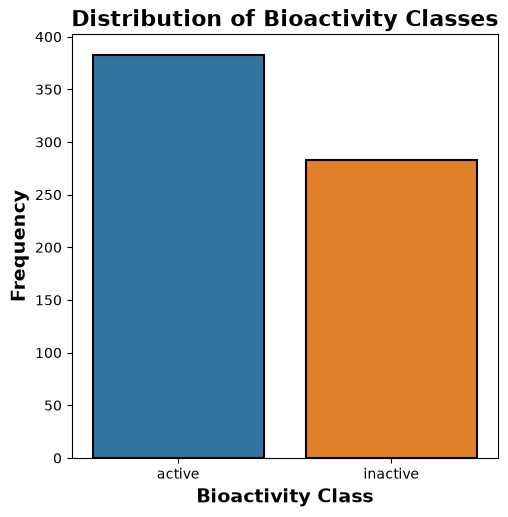

In [24]:
# Create a frequency plot for the 'class' column to visualize the distribution of active, inactive, and intermediate compounds
plt.figure(figsize=(5.5, 5.5))

sns.countplot(x='class', data=df_2class, edgecolor='black', linewidth=1.5, hue = 'class')
plt.xlabel('Bioactivity Class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')
plt.title('Distribution of Bioactivity Classes', fontsize=16, fontweight='bold')

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Distribution_of_Bioactivity_Classes.png",
    dpi=300,
    bbox_inches="tight"
)

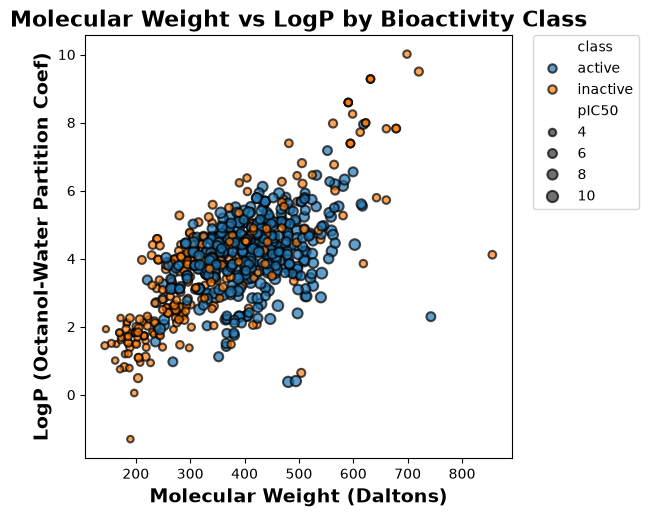

In [25]:
# Create a scatter plot to visualize the relationship between Molecular Weight and LogP, colored by bioactivity class
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(x='MolWt', y='MolLogP', hue='class', size = 'pIC50', 
                data=df_2class, edgecolor='black', linewidth=1.5, alpha=0.7)

plt.xlabel('Molecular Weight (Daltons)', fontsize=14, fontweight='bold')
plt.ylabel('LogP (Octanol-Water Partition Coef)', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0)
plt.title('Molecular Weight vs LogP by Bioactivity Class', fontsize=16, fontweight='bold')  

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Molecular_Weight_vs_LogP_by_Bioactivity_Class.png",
    dpi=300,
    bbox_inches="tight"
)

In [26]:
# Stastical Analysis using Mann-Whitney U Test
def mannwhitney(descriptor, verbose=False):
    # https://machinelearningmastery.com/nonparametric-statistical-significance-tests-in-python/
    from numpy.random import seed
    from scipy.stats import mannwhitneyu

    # seed the random number generator to ensure reproducibility
    seed(1)

    # Select active and inactive compounds
    df = df_2class[[descriptor, 'class']]
    active = df.loc[df['class'] == 'active', descriptor].dropna()
    inactive = df.loc[df['class'] == 'inactive', descriptor].dropna()

    # compare samples
    stat, p = mannwhitneyu(active, inactive)
    #print('Statistics = %.3f, p = %.3f' % (stat,p))

    # interpret
    alpha = 0.05
    if p > alpha:
        interpretation = "Same distribution (fail to reject H0)"
    else:
        interpretation = "Different distribution (reject H0)"

    results = pd.DataFrame({
        'Descriptor' : [descriptor],
        'Statistics' : [stat],
        'p' : [p],
        'alpha' : [alpha],
        'interpretation' : [interpretation]
    })
    filename = 'mannwhitneyu' + descriptor + '.csv'
    results.to_csv(filename)

    return results

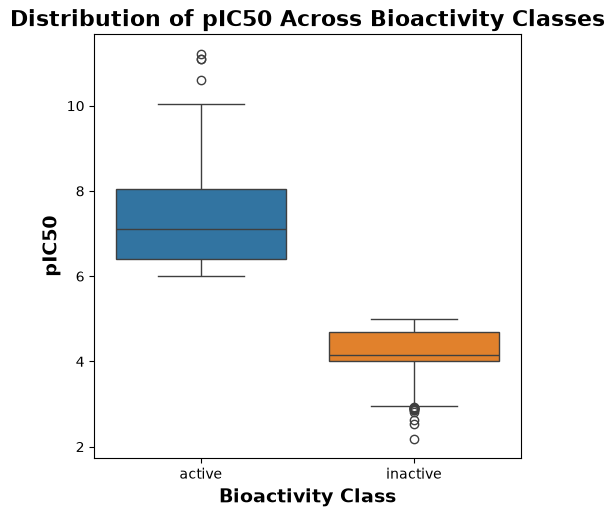

In [27]:
# Create a box plot to visualize the distribution of pIC50 across different bioactivity classes
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='class', y='pIC50', data=df_2class, hue = 'class')

plt.xlabel('Bioactivity Class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50', fontsize=14, fontweight='bold')
plt.title('Distribution of pIC50 Across Bioactivity Classes', fontsize=16, fontweight='bold')

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Plot_IC50.png",
    dpi=300,
    bbox_inches="tight"
)

In [28]:
mannwhitney('pIC50')

,Descriptor,Statistics,p,alpha,interpretation
0,pIC50,108389.0,2.379003e-108,0.05,Different distribution (reject H0)


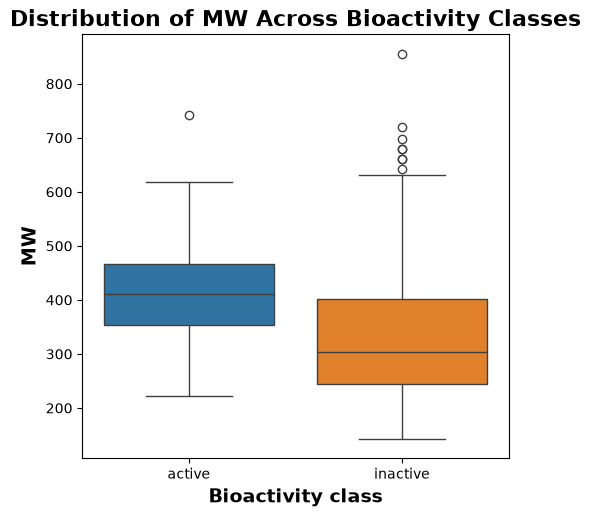

In [29]:
# Create a boxplot for MW and bioactivity class
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'MolWt',  data =  df_2class, hue = 'class')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('MW', fontsize=14, fontweight='bold')
plt.title('Distribution of MW Across Bioactivity Classes', fontsize=16, fontweight='bold')

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Plot_MW.png",
    dpi=300,
    bbox_inches="tight"
)

In [30]:
mannwhitney('MolWt')

,Descriptor,Statistics,p,alpha,interpretation
0,MolWt,79211.5,2.151491e-24,0.05,Different distribution (reject H0)


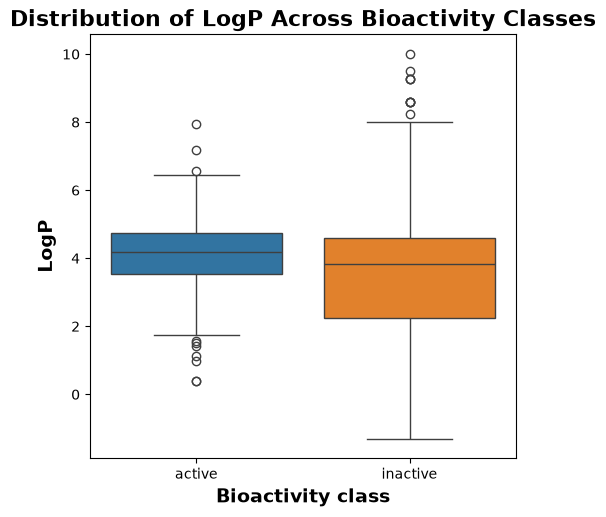

In [31]:
# Create a boxplot for LogP and bioactivity class
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'MolLogP', data = df_2class, hue = 'class')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')
plt.title('Distribution of LogP Across Bioactivity Classes', fontsize=16, fontweight='bold')

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Plot_LogP.png",
    dpi=300,
    bbox_inches="tight"
)

In [32]:
mannwhitney('MolLogP')

,Descriptor,Statistics,p,alpha,interpretation
0,MolLogP,65692.5,0.000003,0.05,Different distribution (reject H0)


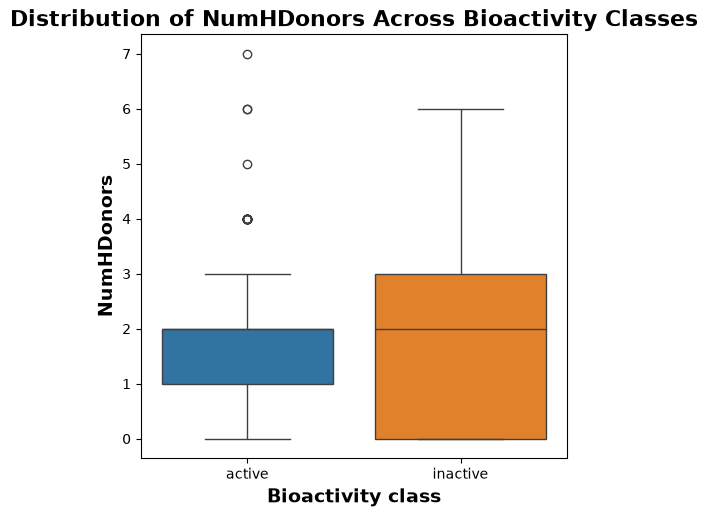

In [33]:
# Create a boxplot for NumHDonors and bioactivity class

plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'NumHDonors', data = df_2class, hue = 'class')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHDonors', fontsize=14, fontweight='bold')
plt.title('Distribution of NumHDonors Across Bioactivity Classes', fontsize=16, fontweight='bold')

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Plot_NumHDonors.png",
    dpi=300,
    bbox_inches="tight"
)

In [34]:
mannwhitney('NumHDonors')

,Descriptor,Statistics,p,alpha,interpretation
0,NumHDonors,62288.0,0.000585,0.05,Different distribution (reject H0)


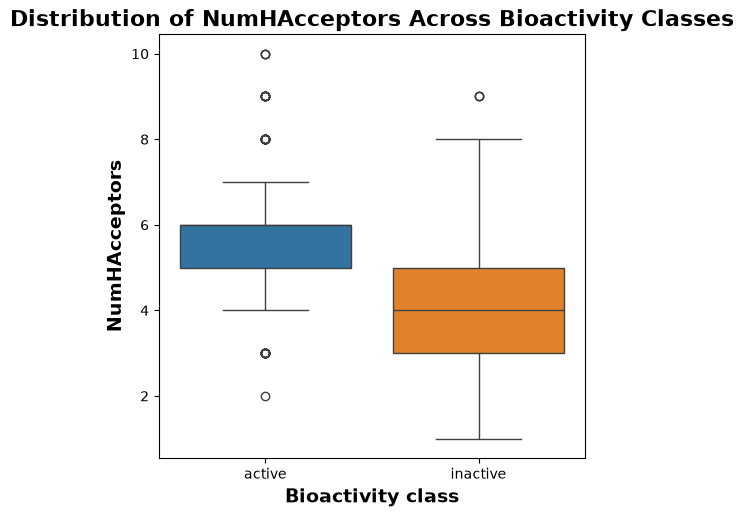

In [35]:
# Create a boxplot for NumHAcceptors and bioactivity class

plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'NumHAcceptors', data = df_2class, hue = 'class')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHAcceptors', fontsize=14, fontweight='bold')
plt.title('Distribution of NumHAcceptors Across Bioactivity Classes', fontsize=16, fontweight='bold')

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Plot_NumHAcceptors.png",
    dpi=300,
    bbox_inches="tight"
)

In [36]:
mannwhitney('NumHAcceptors')

,Descriptor,Statistics,p,alpha,interpretation
0,NumHAcceptors,84128.5,2.653152e-35,0.05,Different distribution (reject H0)


In [37]:
import os
import zipfile
output_dir = r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery"
os.makedirs(output_dir, exist_ok=True)

csv_files = [
    name for name in os.listdir()
    if name.endswith(".csv")
]

pdf_files = [
    name for name in os.listdir()
    if name.endswith(".pdf")
]

zip_path = os.path.join(output_dir, "analysis_results.zip")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in csv_files:
        archive.write(filename, arcname=filename)
    for filename in pdf_files:
            archive.write(filename, arcname=filename)

print(f"Saved {len(csv_files)} CSV file(s) and and {len(pdf_files)} PDF file(s) to: {zip_path}")

Saved 9 CSV file(s) and and 0 PDF file(s) to: D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\analysis_results.zip
